# Finding Elo's Baseline

## Load Data and Run Elo

In [1]:
from cbb_predictor.db import get_connection
from cbb_predictor.features.elo import compute_elo, expected_score

with get_connection(read_only=True) as con:
    team_games = con.sql("SELECT * FROM team_games").df()

BASELINE = {"k": 20, "home_adv": 75, "keep": 0.75}
elo = compute_elo(team_games, **BASELINE)

## Attach Pre Game Ratings

In [2]:
games = team_games.merge(elo, on=["GameID", "TeamID"], how="left")
print(games.shape)
games = games.merge(elo.rename(columns={"TeamID": "OppTeamID", "EloPre": "OppEloPre"}), on=["GameID", "OppTeamID"], how="left")
print(games.shape)
print(games[["EloPre", "OppEloPre"]].isna().sum())

(251956, 41)
(251956, 42)
EloPre       0
OppEloPre    0
dtype: int64


## Calculate Win Probabilities

In [3]:
HOME_ADV = BASELINE["home_adv"]
adv = games["Loc"].map({"H": HOME_ADV, "A": -HOME_ADV, "N": 0})
games["WinProb"] = expected_score(games["EloPre"], games["OppEloPre"], adv)
print(games["WinProb"].between(0, 1).all())   # every probability is between 0 and 1
print(games["WinProb"].mean())                # exactly 0.5 (to rounding)

True
0.49999999999999994


## Score the Results

In [4]:
from sklearn.metrics import log_loss, brier_score_loss

test = games[games["Season"] >= 2004]   # skip 2003 while ratings settle

accuracy = ((test["WinProb"] > 0.5) == test["Win"]).mean()
logloss = log_loss(test["Win"], test["WinProb"])
brier = brier_score_loss(test["Win"], test["WinProb"])

print(f"Rows:     {len(test):,}")
print(f"Accuracy: {accuracy:.1%}")
print(f"Log loss: {logloss:.3f}   (coin flip: 0.693)")
print(f"Brier:    {brier:.3f}   (coin flip: 0.250)")

Rows:     242,596
Accuracy: 71.7%
Log loss: 0.560   (coin flip: 0.693)
Brier:    0.189   (coin flip: 0.250)


## Results
The elo method returns an accuracy of 71.7% and has a log loss of 0.560, this is below the coin flip value of 0.693. My goal from here is to use this as a baseline and have compare every future model to these results. We use Brier and Log Loss because this tracks not just correct predictions but the confidence in those predictions, giving a better understanding of the models capabilities.

## Exploring the Results

### Accuracy per Season

<Axes: title={'center': 'Elo Baseline Accuracy by Season'}, xlabel='Season', ylabel='Accuracy'>

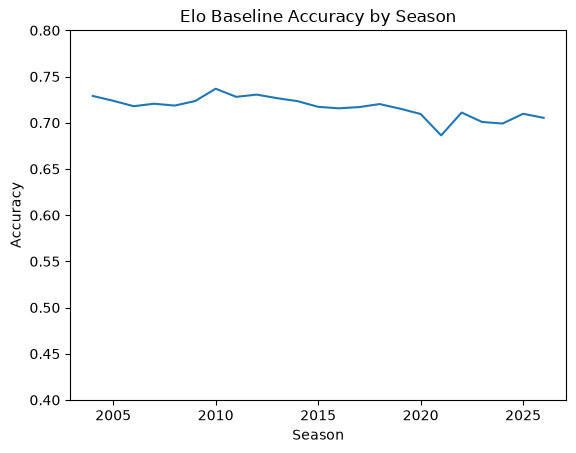

In [5]:
season_accuracy = ((test["WinProb"] > 0.5) == test["Win"]).groupby(test["Season"]).mean()
season_accuracy.plot(title="Elo Baseline Accuracy by Season", ylabel="Accuracy", xlabel="Season", ylim=(0.4, 0.8))


### Note
The accuracy stays at about 71-73% through the seasons, excluding the 2021 season. As mentioned in  notebook 01, 2021 had a noticeably lower home court advantage because of Covid restrictions. This lowers the accuracy of the elo model, especially when using a constant home court advantage.

### Calibration

In [6]:
import pandas as pd

bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
test = test.assign(Bin=pd.cut(test["WinProb"], bins=bins))

calibration = test.groupby("Bin", observed=True).agg(
    predicted=("WinProb", "mean"),
    actual=("Win", "mean"),
    games=("Win", "size"),
)
calibration

,predicted,actual,games
Bin,,,
"(0.0, 0.1]",0.082472,0.013633,1247
"(0.1, 0.2]",0.159875,0.059879,13043
"(0.2, 0.3]",0.253791,0.163556,27483
"(0.3, 0.4]",0.351475,0.291768,37355
"(0.4, 0.5]",0.450416,0.430472,42170
"(0.5, 0.6]",0.549584,0.569528,42170
"(0.6, 0.7]",0.648525,0.708232,37355
"(0.7, 0.8]",0.746209,0.836444,27483
"(0.8, 0.9]",0.840125,0.940121,13043


### Notes
These results show that elo is underconfident. When a team is said to have a 75% chance, that team actually wins 84% of the time. This is because the ratings are too close together, the K variable being set to 20 moves ratings too slowly to separate strong teams from weak ones. College basketball also has a very large gap between the strongest teams and the low major teams. These default settings aren't yet modified to account for this. Below is a chart to show this:

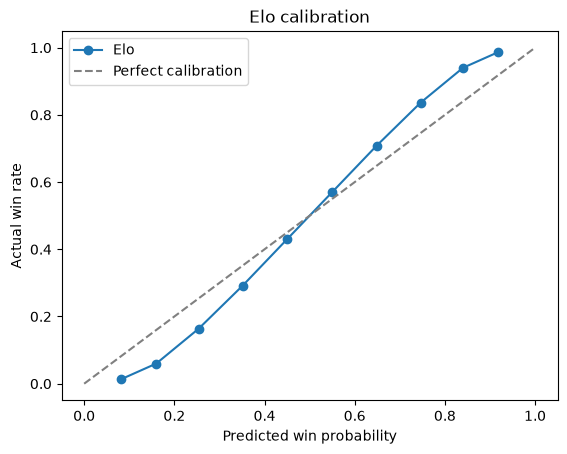

In [7]:
ax = calibration.plot(
    x="predicted", y="actual", marker="o",
    title="Elo calibration", xlabel="Predicted win probability", ylabel="Actual win rate",
    label="Elo",
)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax.legend()

### Sanity Check

In [8]:
with get_connection(read_only=True) as con:
    teams = con.sql("SELECT TeamID, TeamName FROM teams").df()

season_2026 = games[games["Season"] == 2026].sort_values(["Date", "GameID"])
final = season_2026.groupby("TeamID").tail(1)    # each team's last game
top_25 = final.nlargest(25, "EloPre")[["TeamID", "EloPre"]]
top_25 = top_25.merge(teams, on="TeamID", how="left")[["TeamID", "TeamName", "EloPre"]]
top_25

,TeamID,TeamName,EloPre
0,1181,Duke,1858.276483
1,1222,Houston,1828.174294
2,1112,Arizona,1826.934368
3,1276,Michigan,1819.372918
4,1196,Florida,1812.540589
5,1163,Connecticut,1782.474298
6,1211,Gonzaga,1781.344163
7,1385,St John's,1771.844413
8,1388,St Mary's CA,1763.562200
9,1104,Alabama,1760.757984


## Tuning Values

In [9]:
from sklearn.metrics import log_loss

def evaluate(team_games, k, home_adv, keep, first_season, last_season):
    """Run Elo with these settings and score it on the given seasons."""
    elo = compute_elo(team_games, k=k, home_adv=home_adv, keep=keep)
    games = team_games.merge(elo, on=["GameID", "TeamID"], how="left")
    games = games.merge(elo.rename(columns={"TeamID": "OppTeamID", "EloPre": "OppEloPre"}), on=["GameID", "OppTeamID"], how="left")

    adv = games["Loc"].map({"H": home_adv, "A": -home_adv, "N": 0})
    games["WinProb"] = expected_score(games["EloPre"], games["OppEloPre"], adv)

    games = games.loc[games["Season"].between(first_season, last_season)]

    accuracy = ((games["WinProb"] > 0.5) == games["Win"]).mean()
    logloss = log_loss(games["Win"], games["WinProb"])
    return logloss, accuracy

In [10]:
import itertools

results = []
for k, home_adv, keep in itertools.product(
    [20, 30, 40, 50, 60],      # K
    [75, 100, 125],            # home advantage
    [0.5, 0.65, 0.75, 0.85, 0.9, 0.95, 1.0],   # keep
):
    logloss, accuracy = evaluate(team_games, k, home_adv, keep, 2004, 2022)
    results.append({"k": k, "home_adv": home_adv, "keep": keep,
                    "logloss": logloss, "accuracy": accuracy})

results = pd.DataFrame(results).sort_values("logloss")
results.head(10)

,k,home_adv,keep,logloss,accuracy
74,50,100,0.90,0.535602,0.724381
73,50,100,0.85,0.535717,0.724280
94,60,100,0.85,0.536221,0.724645
75,50,100,0.95,0.536364,0.723753
53,40,100,0.90,0.536410,0.723996
95,60,100,0.90,0.536491,0.724473
54,40,100,0.95,0.536681,0.723195
67,50,75,0.90,0.536950,0.721450
52,40,100,0.85,0.537009,0.724229
66,50,75,0.85,0.537178,0.722028


## Testing Tuned Values

In [11]:
logloss, accuracy = evaluate(team_games, 50, 100, 0.90, 2023, 2026)
default_logloss, default_accuracy = evaluate(team_games, 20, 75, 0.75, 2023, 2026)

print(f"Default: logloss={default_logloss:.3f}, accuracy={default_accuracy:.1%}")
print(f"Tuned:    logloss={logloss:.3f}, accuracy={accuracy:.1%}")

Default: logloss=0.572, accuracy=70.4%
Tuned:    logloss=0.557, accuracy=70.8%


### Notes
Tuning did help on the seasons it never saw, going from 0.572 to 0.557 in logloss. This is an improvement but the accuracy and logloss was worse compared to the training data. This is expected as 0.536 was optimistic and the 0.557 is a more accurate result. This can also be explained because of how much CBB has changed in previous years because of the importance of transfer portal.

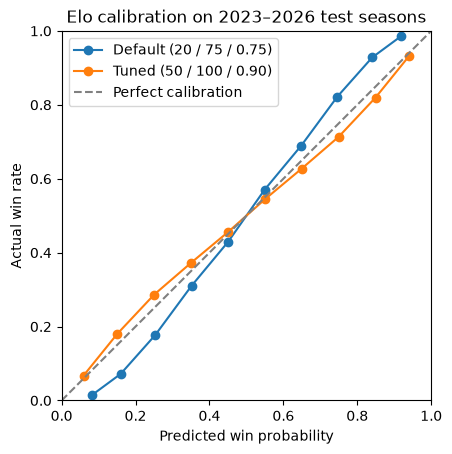

In [12]:
def calibration_table(team_games, k, home_adv, keep, first_season, last_season):
    """Bin Elo win probabilities and compare predicted vs. actual win rates."""
    elo = compute_elo(team_games, k=k, home_adv=home_adv, keep=keep)
    games = team_games.merge(elo, on=["GameID", "TeamID"])
    games = games.merge(elo.rename(columns={"TeamID": "OppTeamID", "EloPre": "OppEloPre"}),
                        on=["GameID", "OppTeamID"])
    adv = games["Loc"].map({"H": home_adv, "A": -home_adv, "N": 0})
    games["WinProb"] = expected_score(games["EloPre"], games["OppEloPre"], adv)
    games = games[games["Season"].between(first_season, last_season)]

    bins = [i / 10 for i in range(11)]
    games = games.assign(Bin=pd.cut(games["WinProb"], bins=bins))
    return games.groupby("Bin", observed=True).agg(
        predicted=("WinProb", "mean"),
        actual=("Win", "mean"),
        games=("Win", "size"),
    )


default = calibration_table(team_games, k=20, home_adv=75, keep=0.75, first_season=2023, last_season=2026)
tuned = calibration_table(team_games, k=50, home_adv=100, keep=0.90, first_season=2023, last_season=2026)

ax = default.plot(x="predicted", y="actual", marker="o", label="Default (20 / 75 / 0.75)")
tuned.plot(x="predicted", y="actual", marker="o", label="Tuned (50 / 100 / 0.90)", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax.set(title="Elo calibration on 2023–2026 test seasons",
       xlabel="Predicted win probability", ylabel="Actual win rate",
       xlim=(0, 1), ylim=(0, 1), aspect="equal")
ax.legend()

## Key Takeaways
* The Elo model is a clean and effective model for predicting games
* There are flaws however and a model that uses a more complete view of the stats can cover this
* Tuning made for a better line on the calibration chart
* After tuning the values, the best defaults are K = 50, home_adv = 100, and keep = 0.9
* This model will be a great baseline to compare other models to